# ML Zoomcamp 2026 — Homework 2: Machine Learning for Regression

Goal: predict `fuel_efficiency_mpg` with linear regression implemented **from scratch** (normal equation, NumPy only), following module 02.

| Q | Answer |
|---|---|
| Q1 Missing values | `horsepower` |
| Q2 Median horsepower | **254** |
| Q3 Filling NAs | **With mean** (2.202 vs 2.205) |
| Q4 Best r | **0** |
| Q5 RMSE std | **0.029** |
| Q6 Test RMSE | **2.236** |

In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from pathlib import Path

local = Path('../../../data/car_fuel_efficiency_2026.csv')
url = 'https://raw.githubusercontent.com/DataTalksClub/machine-learning-zoomcamp/main/cohorts/2026/data/car_fuel_efficiency_2026.csv'
df_raw = pd.read_csv(local if local.exists() else url)
df_raw.shape

(10000, 11)

## Preparing the dataset
Keep only the 4 numeric features + target.

In [2]:
base = ['engine_displacement', 'horsepower', 'vehicle_weight', 'model_year']
target = 'fuel_efficiency_mpg'
df = df_raw[base + [target]].copy()
df.head()

,engine_displacement,horsepower,vehicle_weight,model_year,fuel_efficiency_mpg
0,2180,243.0,3870,2006,31.9
1,2390,272.0,4210,2008,31.3
2,2320,267.0,4240,1996,27.5
3,2130,258.0,4490,1989,28.5
4,2580,304.0,4510,1994,31.0


In [3]:
df.describe().T

,count,mean,std,min,25%,50%,75%,max
engine_displacement,10000.0,2268.807000,183.447355,1590.0,2150.0,2270.0,2390.0,3110.0
horsepower,9123.0,254.446016,22.844613,171.0,239.0,254.0,270.0,334.0
vehicle_weight,10000.0,4286.754000,266.212491,3320.0,4110.0,4280.0,4470.0,5460.0
model_year,10000.0,1999.549500,14.207925,1975.0,1987.0,2000.0,2012.0,2024.0
fuel_efficiency_mpg,10000.0,29.997700,2.930245,19.8,28.0,30.0,31.9,41.2


## EDA — does `fuel_efficiency_mpg` have a long tail?

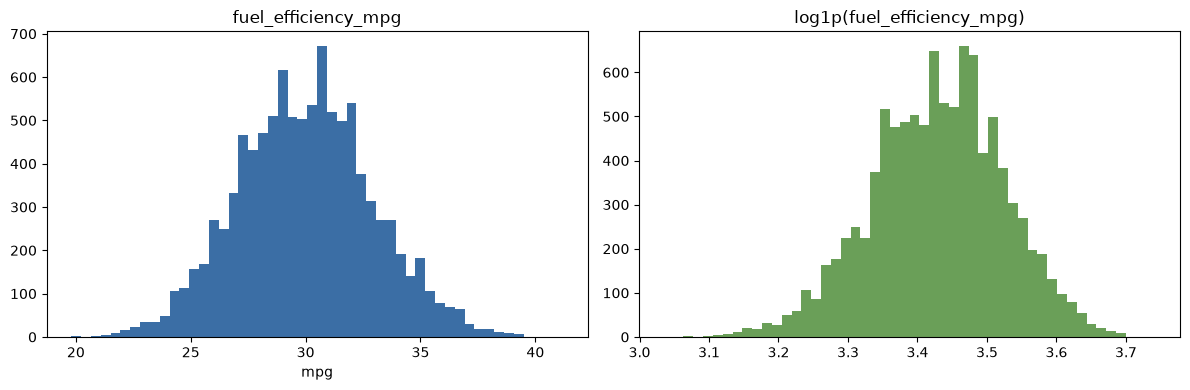

skewness: 0.081


In [4]:
fig, ax = plt.subplots(1, 2, figsize=(12, 4))
ax[0].hist(df[target], bins=50, color='#3b6ea5')
ax[0].set_title('fuel_efficiency_mpg'); ax[0].set_xlabel('mpg')
ax[1].hist(np.log1p(df[target]), bins=50, color='#6a9f58')
ax[1].set_title('log1p(fuel_efficiency_mpg)')
plt.tight_layout(); plt.savefig('images/target_distribution.png', dpi=120); plt.show()
print('skewness:', round(df[target].skew(), 3))

Skewness ≈ 0.08 and mean ≈ median ≈ 30 mpg: the target is roughly **symmetric / bell-shaped with no long tail**, so no log transform is needed (unlike the car-price target in the lectures).

## Question 1 — missing values

In [5]:
df.isnull().sum()

engine_displacement      0
horsepower             877
vehicle_weight           0
model_year               0
fuel_efficiency_mpg      0
dtype: int64

➡️ **`horsepower`** (877 missing, 8.77%).

## Question 2 — median horsepower

In [6]:
df['horsepower'].median()

np.float64(254.0)

➡️ **254**

## Split (exactly as in the lecture)

In [7]:
def split(df, seed):
    n = len(df)
    n_val = int(n * 0.2)
    n_test = int(n * 0.2)
    n_train = n - n_val - n_test
    np.random.seed(seed)
    idx = np.arange(n)
    np.random.shuffle(idx)
    df_train = df.iloc[idx[:n_train]].reset_index(drop=True)
    df_val = df.iloc[idx[n_train:n_train + n_val]].reset_index(drop=True)
    df_test = df.iloc[idx[n_train + n_val:]].reset_index(drop=True)
    return df_train, df_val, df_test

df_train, df_val, df_test = split(df, 42)
len(df_train), len(df_val), len(df_test)

(6000, 2000, 2000)

## Linear regression from scratch

In [8]:
def train_linear_regression(X, y):
    ones = np.ones(X.shape[0])
    X = np.column_stack([ones, X])
    XTX = X.T.dot(X)
    XTX_inv = np.linalg.inv(XTX)
    w_full = XTX_inv.dot(X.T).dot(y)
    return w_full[0], w_full[1:]

def train_linear_regression_reg(X, y, r=0.001):
    ones = np.ones(X.shape[0])
    X = np.column_stack([ones, X])
    XTX = X.T.dot(X)
    XTX = XTX + r * np.eye(XTX.shape[0])
    XTX_inv = np.linalg.inv(XTX)
    w_full = XTX_inv.dot(X.T).dot(y)
    return w_full[0], w_full[1:]

def rmse(y, y_pred):
    return np.sqrt(((y - y_pred) ** 2).mean())

def prepare_X(df, fill_value):
    return df[base].fillna(fill_value).values

y_train, y_val, y_test = df_train[target].values, df_val[target].values, df_test[target].values

## Question 3 — fill with 0 vs. fill with mean
The mean is computed on **training data only** to avoid leakage.

In [9]:
mean_hp = df_train['horsepower'].mean()
print('train mean horsepower:', mean_hp)

for name, fill in [('With 0', 0), ('With mean', mean_hp)]:
    w0, w = train_linear_regression(prepare_X(df_train, fill), y_train)
    score = rmse(y_val, w0 + prepare_X(df_val, fill).dot(w))
    print(f'{name:10s} RMSE = {round(score, 3)}')

train mean horsepower: 254.46338337605272
With 0     RMSE = 2.205
With mean  RMSE = 2.202


➡️ **With mean** (2.202 < 2.205). Filling with 0 creates fake 'zero-horsepower' cars far outside the real range (171–334 hp), which distorts the horsepower coefficient; mean imputation keeps those rows inside the data distribution.

## Question 4 — regularization

In [10]:
X_train, X_val = prepare_X(df_train, 0), prepare_X(df_val, 0)
scores = {}
for r in [0, 0.01, 0.1, 1, 5, 10, 100]:
    w0, w = train_linear_regression_reg(X_train, y_train, r=r)
    scores[r] = round(rmse(y_val, w0 + X_val.dot(w)), 4)
    print(f'r={r:<6} w0={w0:10.3f}  RMSE={scores[r]}')
best = min(scores.values())
print('best r:', min(r for r, s in scores.items() if s == best))

r=0      w0=  -153.885  RMSE=2.2053
r=0.01   w0=  -148.309  RMSE=2.2058
r=0.1    w0=  -111.839  RMSE=2.2241
r=1      w0=   -32.332  RMSE=2.3492
r=5      w0=    -7.773  RMSE=2.4094
r=10     w0=    -3.987  RMSE=2.4195
r=100    w0=    -0.408  RMSE=2.4292
best r: 0


➡️ **r = 0**.

**Why does regularization *hurt* here?** The lecture implementation adds `r` to the *whole* diagonal of $X^TX$, including the intercept term. Because `model_year ≈ 2000` is unscaled, the model needs a large negative intercept (≈ −154) to offset `0.102 × 2000 ≈ 204`. Penalizing the intercept shrinks it toward 0 and the fit degrades. If the intercept is left unpenalized, RMSE stays at 2.2053 for every r:

In [11]:
X1 = np.column_stack([np.ones(len(X_train)), X_train])
for r in [0, 0.01, 1, 100]:
    P = r * np.eye(X1.shape[1]); P[0, 0] = 0      # do not penalize bias
    wf = np.linalg.solve(X1.T @ X1 + P, X1.T @ y_train)
    print(f'r={r:<5} intercept-unpenalized RMSE = {rmse(y_val, wf[0] + X_val @ wf[1:]):.4f}')
print(f'condition number of XᵀX: {np.linalg.cond(X1.T @ X1):.2e}')

r=0     intercept-unpenalized RMSE = 2.2053
r=0.01  intercept-unpenalized RMSE = 2.2053
r=1     intercept-unpenalized RMSE = 2.2053
r=100   intercept-unpenalized RMSE = 2.2053
condition number of XᵀX: 6.23e+11


## Question 5 — seed stability

0 2.2392
1 2.2021
2 2.1634
3 2.2044
4 2.2019
5 2.2458
6 2.2697
7 2.1908
8 2.2166
9 2.207
std: 0.029


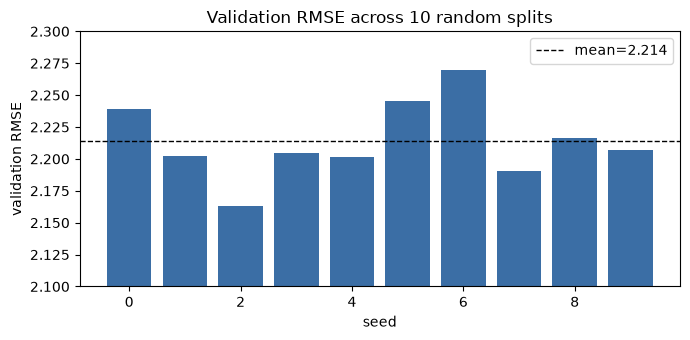

In [12]:
seed_scores = []
for seed in range(10):
    tr, va, _ = split(df, seed)
    w0, w = train_linear_regression(prepare_X(tr, 0), tr[target].values)
    seed_scores.append(rmse(va[target].values, w0 + prepare_X(va, 0).dot(w)))

for s, sc in enumerate(seed_scores):
    print(s, round(sc, 4))
print('std:', round(np.std(seed_scores), 3))

plt.figure(figsize=(7, 3.5))
plt.bar(range(10), seed_scores, color='#3b6ea5')
plt.axhline(np.mean(seed_scores), color='k', ls='--', lw=1, label=f'mean={np.mean(seed_scores):.3f}')
plt.ylim(2.1, 2.3); plt.xlabel('seed'); plt.ylabel('validation RMSE'); plt.legend()
plt.title('Validation RMSE across 10 random splits')
plt.tight_layout(); plt.savefig('images/seed_rmse.png', dpi=120); plt.show()

➡️ **0.029** — about 1.3% of the mean RMSE (≈2.21), so the model is **stable** across splits.

## Question 6 — final model on test

In [13]:
tr, va, te = split(df, 9)
df_full = pd.concat([tr, va]).reset_index(drop=True)
w0, w = train_linear_regression_reg(prepare_X(df_full, 0), df_full[target].values, r=0.001)
test_rmse = rmse(te[target].values, w0 + prepare_X(te, 0).dot(w))
print('test RMSE:', round(test_rmse, 3))

test RMSE: 2.236


➡️ **2.236** — i.e. predictions are off by ≈2.2 mpg on average, against a target std of ≈2.93 mpg.